In [19]:
# จัดการข้อมูล
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

# ตั้งค่าการแสดงผล
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [20]:
# โหลดข้อมูล
df = pd.read_csv("C04_employee_turnover_classification.xlsx - Raw_Data.csv")

# แสดงข้อมูล 5 แถวแรก
df.head()

,employee_id,age,monthly_income,years_company,overtime,job_satisfaction,training_hours,left_company
0,E00720,35.0,33096.6,19.0,No,5.0,27.0,0
1,E00199,39.0,15729.0,3.0,Yes,1.0,31.4,0
2,E00771,42.0,34675.9,7.0,No,4.0,10.9,0
3,E00944,22.0,12000.0,1.0,Yes,2.0,28.4,1
4,E00824,43.0,40022.8,2.0,Yes,4.0,44.7,0


In [21]:
# จำนวนแถวและคอลัมน์
print("Shape:", df.shape)

# ชื่อคอลัมน์
print("\nColumns:")
print(df.columns.tolist())

# ประเภทข้อมูล
print("\nData Types:")
print(df.dtypes)

# ข้อมูลเบื้องต้น
df.info()

Shape: (1062, 8)

Columns:
['employee_id', 'age', 'monthly_income', 'years_company', 'overtime', 'job_satisfaction', 'training_hours', 'left_company']

Data Types:
employee_id             str
age                 float64
monthly_income      float64
years_company       float64
overtime                str
job_satisfaction    float64
training_hours      float64
left_company          int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 1062 entries, 0 to 1061
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   employee_id       1062 non-null   str    
 1   age               1058 non-null   float64
 2   monthly_income    1056 non-null   float64
 3   years_company     1060 non-null   float64
 4   overtime          1055 non-null   str    
 5   job_satisfaction  1057 non-null   float64
 6   training_hours    1058 non-null   float64
 7   left_company      1062 non-null   int64  
dtypes: float64(5), int64(1), str

In [22]:
# ตรวจสอบ Missing Values
missing = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percentage": df.isnull().mean() * 100
})

missing.sort_values(
    by="Missing",
    ascending=False
)

,Missing,Percentage
overtime,7,0.659134
monthly_income,6,0.564972
job_satisfaction,5,0.470810
age,4,0.376648
training_hours,4,0.376648
years_company,2,0.188324
employee_id,0,0.000000
left_company,0,0.000000


In [23]:
# ตรวจสอบจำนวนแถวที่ซ้ำกัน
print("Duplicate Rows:", df.duplicated().sum())

# ตรวจสอบรหัสพนักงานที่ซ้ำ
print("Duplicate Employee ID:",
      df["employee_id"].duplicated().sum())

Duplicate Rows: 12
Duplicate Employee ID: 12


In [24]:
# ทำความสะอาดข้อมูล overtime
df["overtime"] = (
    df["overtime"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# แปลงเป็นมาตรฐาน
df["overtime"] = df["overtime"].replace({
    "yes": "Yes",
    "no": "No"
})

# ตรวจสอบค่าที่มีอยู่
print(df["overtime"].value_counts(dropna=False))

overtime
No      536
Yes     519
<NA>      7
Name: count, dtype: int64[pyarrow]


In [25]:
# สถิติเบื้องต้น
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1058.0,40.124008,10.819477,22.0,31.000,40.0,49.000,67.2
monthly_income,1056.0,32427.342330,13455.434288,12000.0,22885.350,31405.9,40520.625,84276.8
years_company,1060.0,10.052830,5.993311,0.0,5.000,10.0,15.000,20.0
job_satisfaction,1057.0,2.997729,1.416540,1.0,2.000,3.0,4.000,9.0
training_hours,1058.0,25.112665,11.997309,0.0,16.325,25.1,33.600,65.1
left_company,1062.0,0.209040,0.406814,0.0,0.000,0.0,0.000,1.0


In [26]:
# ตรวจสอบค่าที่ไม่สมเหตุสมผล
print("Age < 18:", (df["age"] < 18).sum())
print("Age > 100:", (df["age"] > 100).sum())

print("Negative Income:",
      (df["monthly_income"] < 0).sum())

print("Negative Years:",
      (df["years_company"] < 0).sum())

print("Invalid Satisfaction:",
      (~df["job_satisfaction"].between(1, 5)).sum())

Age < 18: 0
Age > 100: 0
Negative Income: 0
Negative Years: 0
Invalid Satisfaction: 6


left_company
0    840
1    222
Name: count, dtype: int64
left_company
0    79.096045
1    20.903955
Name: proportion, dtype: float64


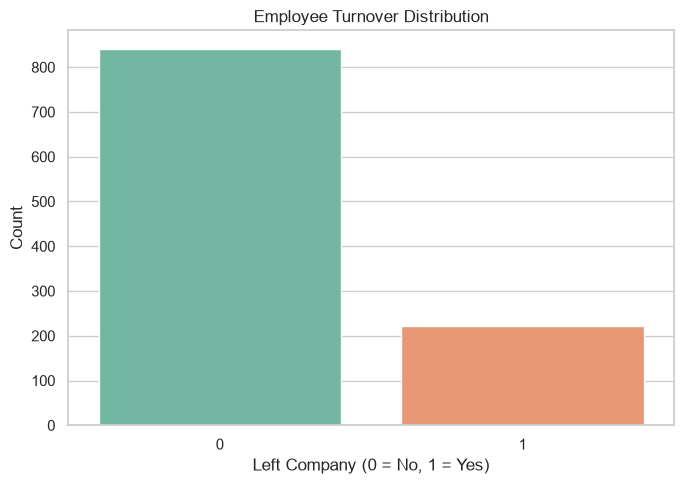

In [27]:
# นับจำนวนพนักงานแต่ละกลุ่ม
print(df["left_company"].value_counts())

# คำนวณเปอร์เซ็นต์
print(df["left_company"].value_counts(normalize=True) * 100)

# Visualization
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="left_company",
    hue="left_company",
    palette="Set2",
    legend=False
)

plt.title("Employee Turnover Distribution")
plt.xlabel("Left Company (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

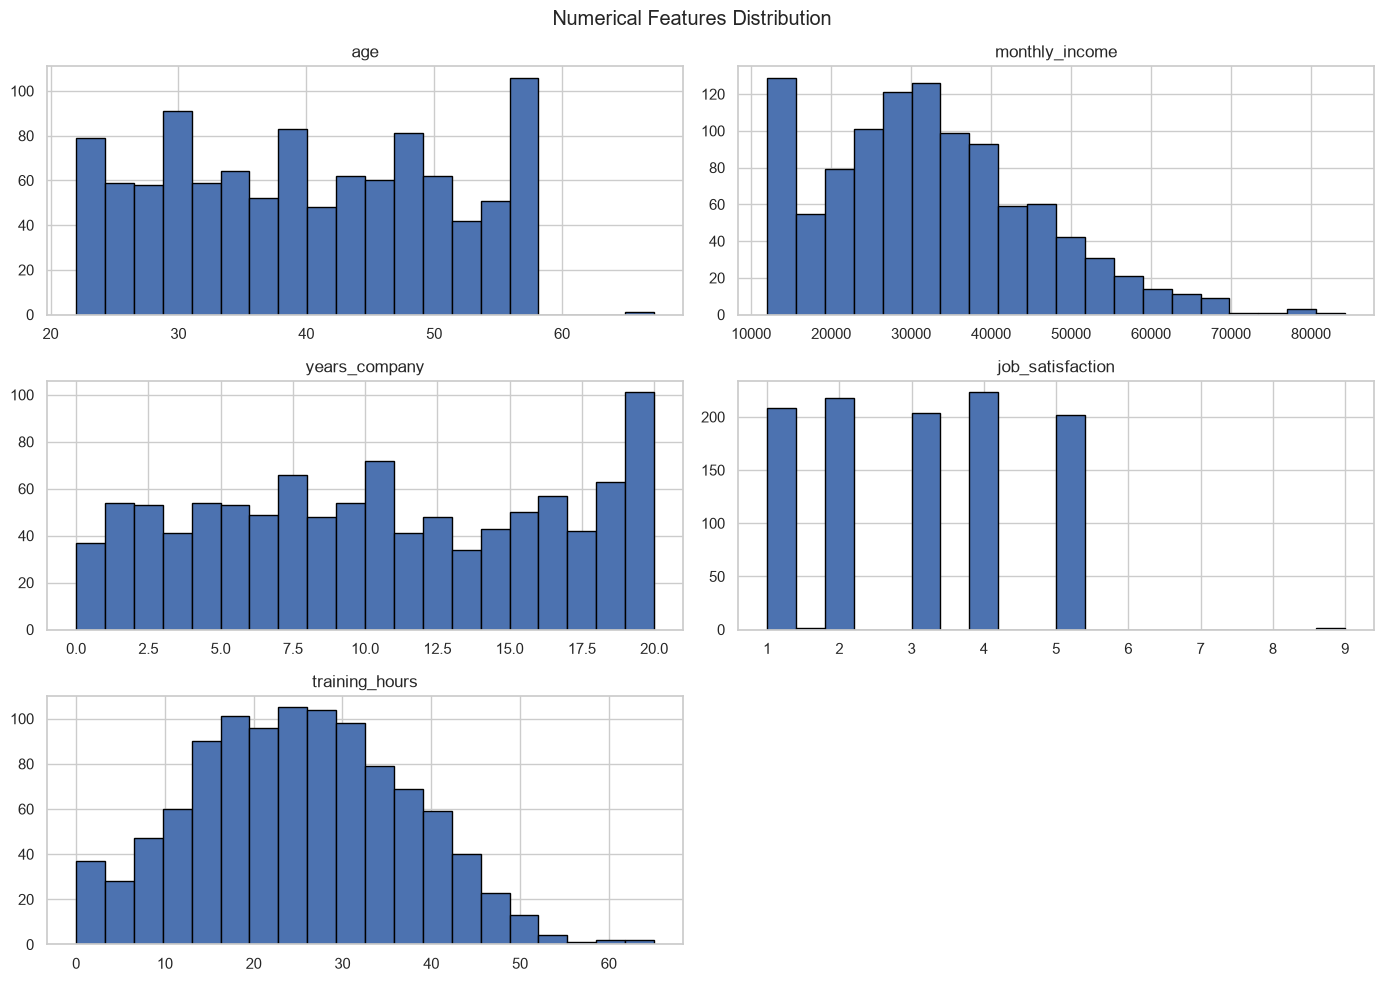

In [28]:
numeric_columns = [
    "age",
    "monthly_income",
    "years_company",
    "job_satisfaction",
    "training_hours"
]

df[numeric_columns].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Numerical Features Distribution")
plt.tight_layout()
plt.show()

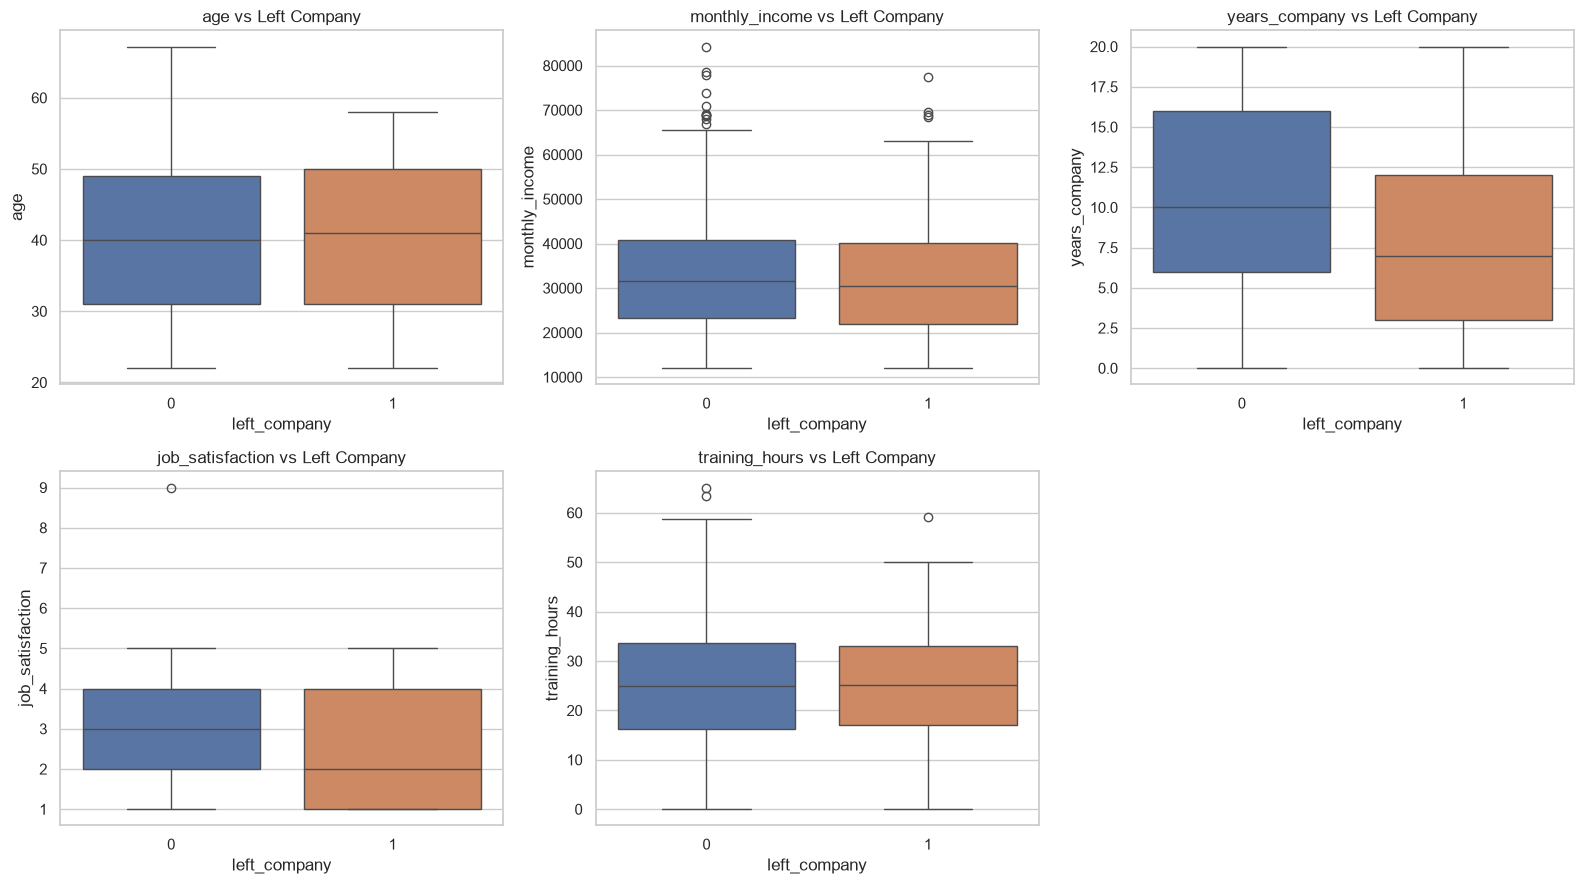

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, col in enumerate(numeric_columns):
    sns.boxplot(
        data=df,
        x="left_company",
        y=col,
        hue="left_company",
        legend=False,
        ax=axes[i // 3, i % 3]
    )

    axes[i // 3, i % 3].set_title(
        f"{col} vs Left Company"
    )

axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

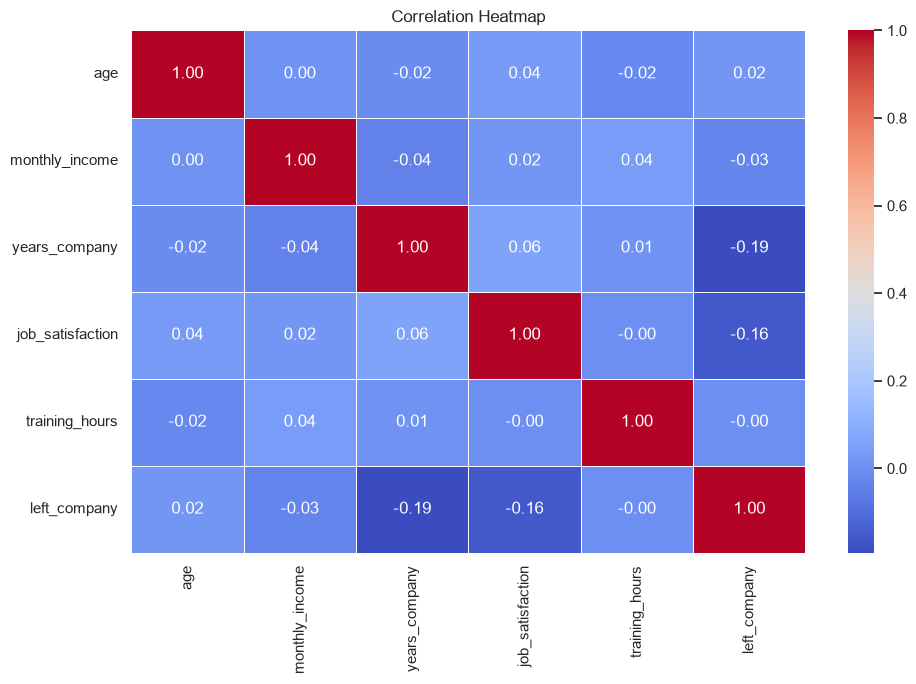

In [30]:
# เลือกเฉพาะตัวแปรตัวเลข
corr = df[numeric_columns + ["left_company"]].corr(
    numeric_only=True
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [31]:
# Features
feature_columns = [
    "age",
    "monthly_income",
    "years_company",
    "overtime",
    "job_satisfaction",
    "training_hours"
]

# Target
target_column = "left_company"

X = df[feature_columns].copy()
y = df[target_column].copy()

# แปลง overtime เป็นตัวเลข
X["overtime"] = X["overtime"].map({
    "Yes": 1,
    "No": 0
})

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
    age  monthly_income  years_company  overtime  job_satisfaction  \
0  35.0         33096.6           19.0       0.0               5.0   
1  39.0         15729.0            3.0       1.0               1.0   
2  42.0         34675.9            7.0       0.0               4.0   
3  22.0         12000.0            1.0       1.0               2.0   
4  43.0         40022.8            2.0       1.0               4.0   

   training_hours  
0            27.0  
1            31.4  
2            10.9  
3            28.4  
4            44.7  

Target:
0    0
1    0
2    0
3    1
4    0
Name: left_company, dtype: int64


In [32]:
print(y.value_counts(dropna=False))

left_company
0    840
1    222
Name: count, dtype: int64


In [33]:
# แบ่งข้อมูล
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining Target:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target:")
print(y_test.value_counts(normalize=True))

X_train: (849, 6)
X_test: (213, 6)
y_train: (849,)
y_test: (213,)

Training Target:
left_company
0    0.791519
1    0.208481
Name: proportion, dtype: float64

Testing Target:
left_company
0    0.788732
1    0.211268
Name: proportion, dtype: float64


In [34]:
from sklearn.pipeline import Pipeline

# Logistic Regression
lr_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Decision Tree
dt_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

# KNN
knn_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ))
])

# Random Forest
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# รวมโมเดล
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "KNN": knn_model,
    "Random Forest": rf_model
}

In [35]:

# 1. Train Models ก่อน
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully")

# 2. Model Evaluation
results = []

for name, model in models.items():

    # Predict
    y_pred = model.predict(X_test)

    # Predict Probability
    y_prob = model.predict_proba(X_test)[:, 1]

    # Evaluation
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# 3. แสดงผลการเปรียบเทียบ
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

results_df.round(4)

Logistic Regression trained successfully
Decision Tree trained successfully
KNN trained successfully
Random Forest trained successfully


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7136,0.3974,0.6889,0.5041,0.7488
1,Random Forest,0.6808,0.3614,0.6667,0.4688,0.7196
2,Decision Tree,0.6432,0.3218,0.6222,0.4242,0.6192
3,KNN,0.7700,0.4167,0.2222,0.2899,0.6634


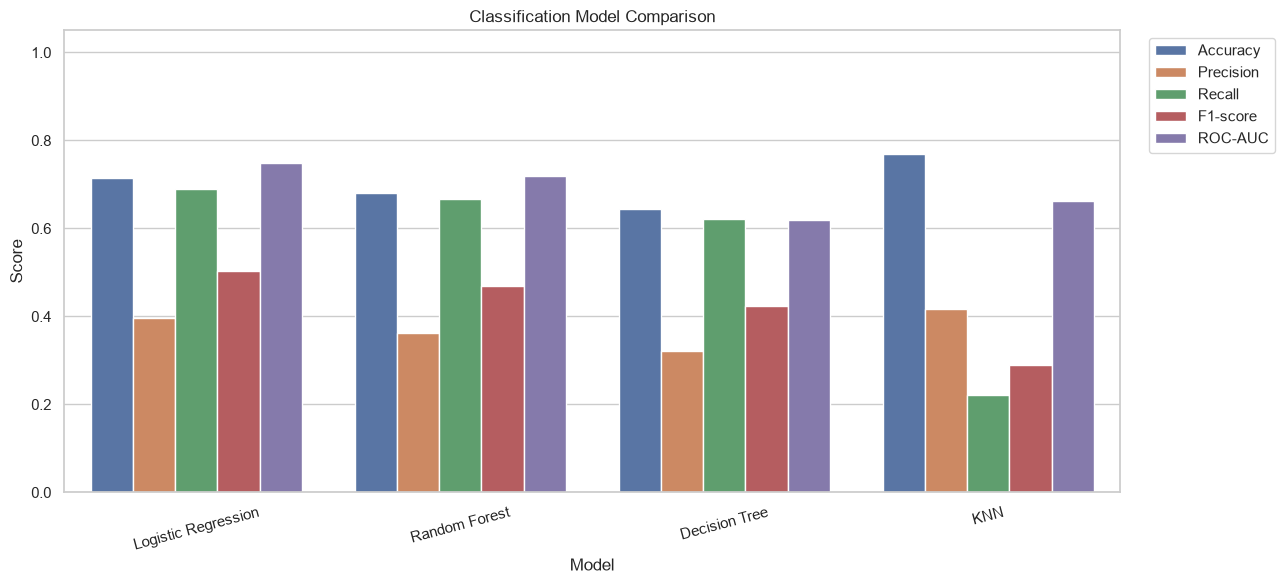

In [37]:
# เปรียบเทียบ Metrics
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Classification Model Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

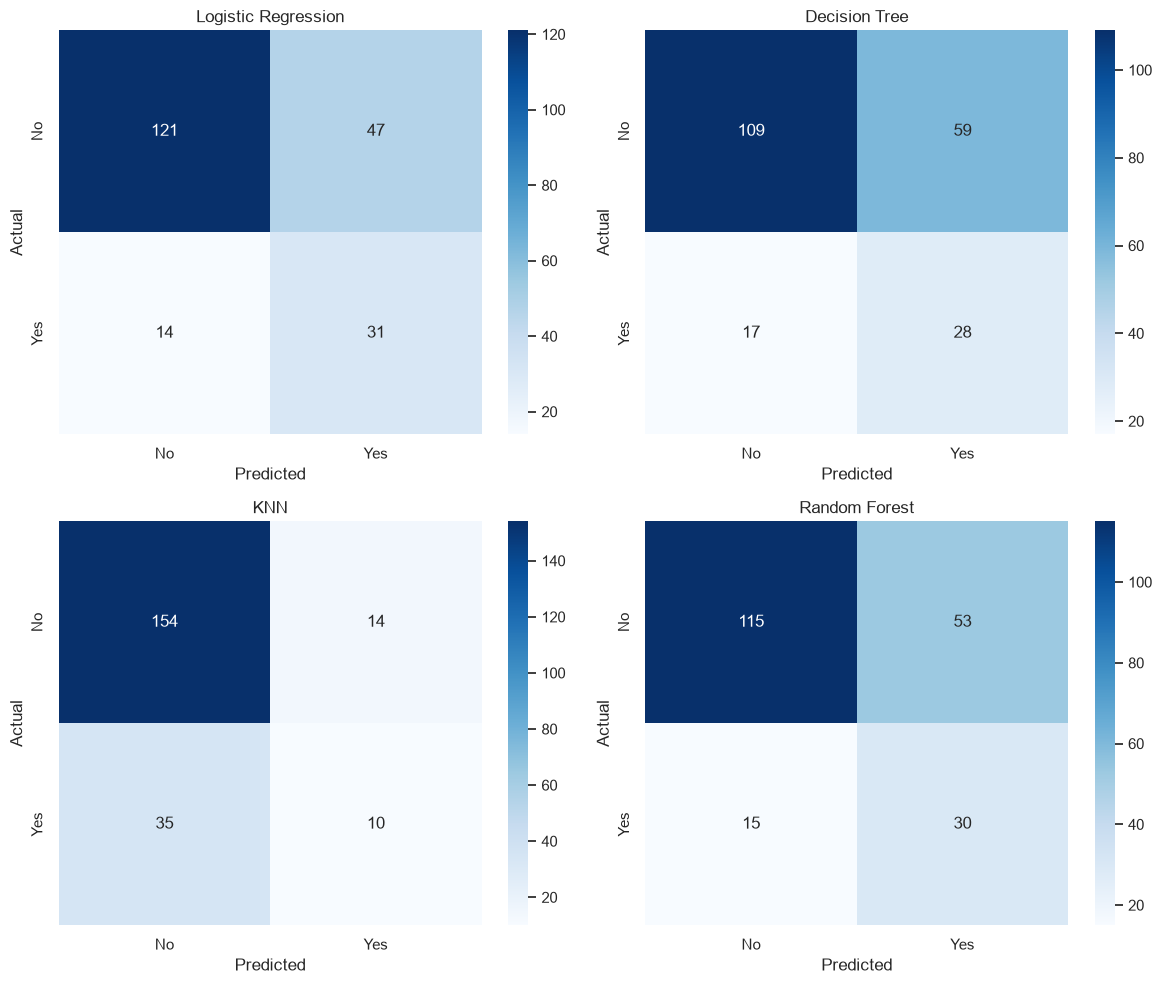

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, model) in zip(axes.flatten(), models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [39]:
for name, model in models.items():

    print("=" * 60)
    print(name)
    print("=" * 60)

    y_pred = model.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Not Left", "Left"],
        zero_division=0
    ))

Logistic Regression
              precision    recall  f1-score   support

    Not Left       0.90      0.72      0.80       168
        Left       0.40      0.69      0.50        45

    accuracy                           0.71       213
   macro avg       0.65      0.70      0.65       213
weighted avg       0.79      0.71      0.74       213

Decision Tree
              precision    recall  f1-score   support

    Not Left       0.87      0.65      0.74       168
        Left       0.32      0.62      0.42        45

    accuracy                           0.64       213
   macro avg       0.59      0.64      0.58       213
weighted avg       0.75      0.64      0.67       213

KNN
              precision    recall  f1-score   support

    Not Left       0.81      0.92      0.86       168
        Left       0.42      0.22      0.29        45

    accuracy                           0.77       213
   macro avg       0.62      0.57      0.58       213
weighted avg       0.73      0.77   

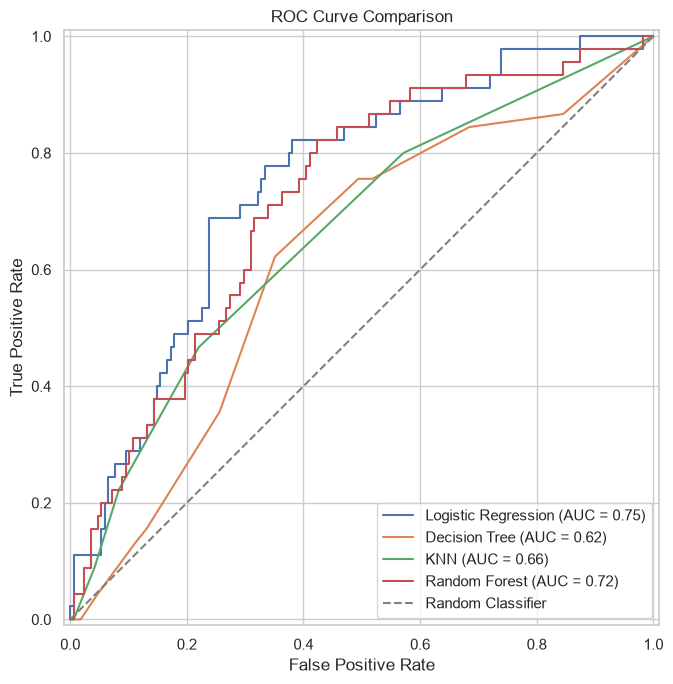

In [40]:
plt.figure(figsize=(9, 7))

ax = plt.gca()

for name, model in models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

            Feature  Importance
3          overtime    0.279226
2     years_company    0.245867
1    monthly_income    0.142759
5    training_hours    0.117213
4  job_satisfaction    0.108265
0               age    0.106669


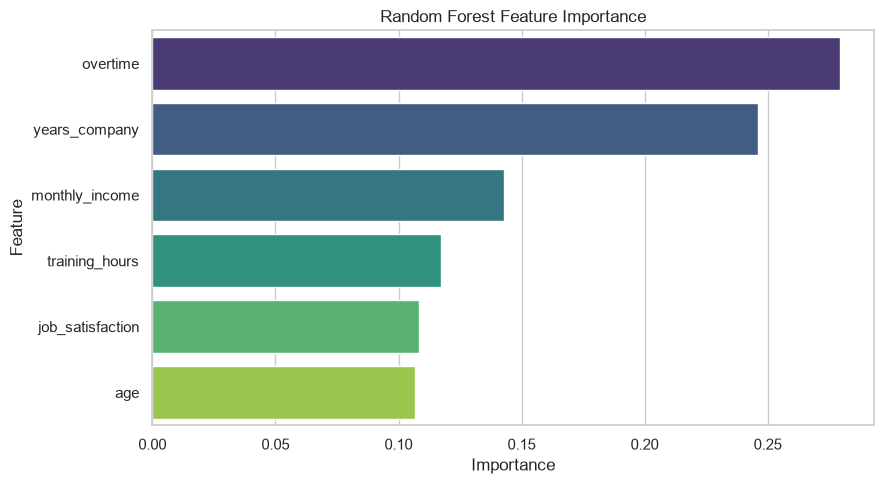

In [41]:
# Random Forest Feature Importance
rf = models["Random Forest"].named_steps["model"]

importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [42]:
# ข้อมูลพนักงานตัวอย่าง
new_employee = pd.DataFrame([{
    "age": 30,
    "monthly_income": 25000,
    "years_company": 3,
    "overtime": 1,
    "job_satisfaction": 2,
    "training_hours": 15
}])

# เลือกโมเดล
model = models["Random Forest"]

# ทำนาย
prediction = model.predict(new_employee)[0]
probability = model.predict_proba(new_employee)[0][1]

print("Prediction:", prediction)
print("Probability of leaving:", round(probability, 4))

if prediction == 1:
    print("Predicted Class: Left Company")
else:
    print("Predicted Class: Not Left")

Prediction: 1
Probability of leaving: 0.7011
Predicted Class: Left Company
